# Chapter 15: Deep Learning on Unseen Data: Federated Learning

**Tujuan pembelajaran:**
1. Menjelaskan perbedaan pelatihan terpusat dan *federated learning*.
2. Melatih model klasifikasi spam sederhana pada data lokal dan menggabungkan model dari beberapa klien.
3. Mendemonstrasikan bagaimana pembaruan bobot dapat membocorkan informasi pada contoh yang sangat sederhana.
4. Memahami *secure aggregation* dan *homomorphic encryption*.
5. Menilai batas perlindungan privasi: federated learning **mengurangi kebutuhan memindahkan data mentah, tetapi tidak otomatis menjamin privasi**.

## 1. Masalah privasi dalam deep learning

Model belajar dari data, tetapi data dapat memuat informasi sensitif: pesan pribadi, rekam medis, lokasi, atau kebiasaan pengguna. Pelatihan terpusat biasanya mengharuskan data dikumpulkan ke satu tempat; ini dapat meningkatkan risiko akses yang tidak sah, penggunaan sekunder, dan pelanggaran aturan berbagi data.

Pertanyaan yang diajukan bab ini adalah: **bisakah model belajar dari beberapa kumpulan data tanpa mengumpulkan seluruh data mentahnya?** Federated learning mencoba menjawab pertanyaan tersebut.

Penting membedakan dua klaim:
- **Klaim yang didukung desain:** data mentah dapat tetap berada di perangkat/organisasi pemiliknya.
- **Klaim yang tidak otomatis benar:** tidak ada informasi pribadi yang dapat bocor. Gradien atau pembaruan bobot tetap dapat mengandung informasi tentang data lokal.

## 2. Alur *federated learning*

Siklus konseptual:

1. Koordinator mengirim parameter model awal ke klien (misalnya Bob, Alice, dan Sue).
2. Setiap klien melatih salinan model menggunakan data lokalnya; data mentah tidak dikirim ke koordinator.
3. Klien mengirim pembaruan atau parameter model hasil pelatihan.
4. Koordinator menggabungkan pembaruan, misalnya dengan rata-rata (*federated averaging*), lalu memulai putaran berikutnya.

Pada contoh buku, model hasil tiap klien dirata-ratakan setelah satu putaran pelatihan. Sistem nyata dapat menggabungkan gradien atau delta parameter dan perlu menangani ukuran data klien yang berbeda, klien yang terputus, serta perangkat yang heterogen.

**Catatan:** notebook ini menggunakan rata-rata model dari tiga klien dengan ukuran data yang dibuat hampir sama agar mekanismenya mudah diperiksa.

In [1]:
import re
import copy
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

SEED = 15
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)
print('NumPy:', np.__version__)
print('Seed eksperimen:', SEED)

NumPy: 2.3.5
Seed eksperimen: 15


## 3. Menyiapkan contoh klasifikasi email spam 

Buku menggunakan data Enron yang dipisah menjadi `spam.txt` dan `ham.txt`, lalu setiap email direpresentasikan sebagai daftar indeks kata. Model contoh menggunakan embedding satu dimensi: bobot setiap kata dijumlahkan dan hasilnya dilewatkan ke sigmoid untuk menghasilkan probabilitas spam.

Di sini kita memakai email **sintetis** dengan pola kata yang sengaja sederhana. Tujuannya adalah memeriksa alur pembelajaran dan privasi, bukan membangun filter spam yang layak produksi.

In [2]:
# Membuat data sintetis yang reproducible; tidak memuat email pribadi atau korpus Enron.
spam_templates = [
    'free {prize} claim now',
    'urgent winner click {link} to claim {prize}',
    'limited offer earn {money} today',
    'congratulations you won {prize} reply now',
    'verify account to receive free {prize}',
    'exclusive deal get {item} for free',
    'claim cash bonus before offer expires',
    'winner selected open {link} now',
    'cheap {item} available buy today',
    'act now receive cash reward',
]
ham_templates = [
    'hi {person} please review the {document} today',
    'meeting about {project} is scheduled for {time}',
    'please send the {document} before the meeting',
    'thanks for your help with the {project}',
    'can we discuss the report during the meeting',
    'the team will review the schedule tomorrow',
    'hello {person} I attached the notes from today',
    'please confirm the time for our project meeting',
    'I will send the updated report this afternoon',
    'thanks I received your message and will reply soon',
]
choices = {
    'prize': ['gift', 'phone', 'voucher', 'ticket', 'reward'],
    'link': ['website', 'page', 'offer', 'form'],
    'money': ['cash', 'income', 'profit', 'bonus'],
    'item': ['phone', 'watch', 'tablet', 'laptop'],
    'person': ['sam', 'lee', 'jordan', 'taylor', 'alex'],
    'document': ['report', 'file', 'draft', 'document'],
    'project': ['design', 'research', 'launch', 'budget'],
    'time': ['monday', 'tuesday', 'morning', 'afternoon'],
}

def buat_email(template, local_rng):
    hasil = template
    for slot, opsi in choices.items():
        hasil = hasil.replace('{' + slot + '}', str(local_rng.choice(opsi)))
    # Tambahkan variasi ringan agar tidak seluruh contoh identik.
    if local_rng.random() < 0.35:
        hasil += ' ' + str(local_rng.choice(['please', 'thanks', 'today', 'hello']))
    return hasil

local_rng = np.random.default_rng(SEED)
emails, labels = [], []
for _ in range(400):
    emails.append(buat_email(str(local_rng.choice(spam_templates)), local_rng)); labels.append(1)
    emails.append(buat_email(str(local_rng.choice(ham_templates)), local_rng)); labels.append(0)

# Tokenisasi sederhana dan representasi set kata, sejalan dengan pendekatan buku.
def tokenisasi(teks):
    return sorted(set(re.findall(r'[a-z]+', teks.lower())))

token_emails = [tokenisasi(e) for e in emails]
labels = np.asarray(labels, dtype=np.float64)

# Vocabulary dibuat dari korpus sintetis ditambah token untuk demonstrasi serangan pada bagian 7.
attack_tokens = tokenisasi('my computer password is pizza')
vocab = sorted(set(w for row in token_emails for w in row) | set(attack_tokens) | {'<unk>'})
w2i = {w: i for i, w in enumerate(vocab)}
X = [[w2i.get(w, w2i['<unk>']) for w in row] for row in token_emails]
print('Jumlah email:', len(X))
print('Jumlah kata unik:', len(vocab))
print('Contoh email:', emails[0], '| label:', int(labels[0]), '(1=spam, 0=ham)')

Jumlah email: 800
Jumlah kata unik: 103
Contoh email: act now receive cash reward today | label: 1 (1=spam, 0=ham)


## 4. Membagi data latih dan data uji

Data dibagi secara terstratifikasi agar kedua kelas tetap terwakili pada data latih dan uji. Email sintetis dibuat dari template terbatas, sehingga pola pada data uji masih mirip dengan data latih. Oleh karena itu, hasil hanya menilai implementasi pada tugas mainan ini; hasilnya tidak menunjukkan kemampuan generalisasi pada email nyata.

In [3]:
# Pemisahan terstratifikasi dengan seed tetap.
idx_train, idx_test = [], []
for label in (0, 1):
    idx = np.flatnonzero(labels == label)
    local_rng.shuffle(idx)
    cut = int(0.8 * len(idx))
    idx_train.extend(idx[:cut].tolist())
    idx_test.extend(idx[cut:].tolist())
local_rng.shuffle(idx_train)
local_rng.shuffle(idx_test)

X_train = [X[i] for i in idx_train]
y_train = labels[idx_train]
X_test = [X[i] for i in idx_test]
y_test = labels[idx_test]
print('Data latih:', len(X_train), '| data uji:', len(X_test))
print('Proporsi spam latih:', y_train.mean().round(3), '| uji:', y_test.mean().round(3))

Data latih: 640 | data uji: 160
Proporsi spam latih: 0.5 | uji: 0.5


## 5. Model embedding skalar dan pelatihan terpusat

Untuk email dengan token unik $w_1,\ldots,w_m$, model sederhana pada bab ini dapat ditulis sebagai

$$s=\sum_{j=1}^{m} e_{w_j},\qquad \hat y=\sigma(s)=\frac{1}{1+e^{-s}}.$$

Setiap kata memiliki satu bobot skalar $e_w$. Kita menggunakan *mean squared error* (MSE) seperti contoh buku, lalu melakukan SGD. Untuk satu contoh, jika $L=(\hat y-y)^2$, maka

$$\frac{\partial L}{\partial s}=2(\hat y-y)\hat y(1-\hat y).$$

Turunan ini ditambahkan ke bobot setiap kata yang muncul pada email. Implementasi dibuat ringkas agar pembaruan parameter dapat dilihat langsung.

In [4]:
def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1.0 / (1.0 + np.exp(-z))

def prediksi_satu(weights, token_ids):
    if len(token_ids) == 0:
        return 0.5
    return float(sigmoid(weights[token_ids].sum()))

def loss_dataset(weights, data, targets):
    preds = np.array([prediksi_satu(weights, row) for row in data])
    return float(np.mean((preds - targets) ** 2))

def evaluasi(weights, data, targets):
    probs = np.array([prediksi_satu(weights, row) for row in data])
    pred = (probs >= 0.5).astype(int)
    return {
        'loss_mse': float(np.mean((probs - targets) ** 2)),
        'akurasi': float(np.mean(pred == targets)),
        'prediksi': probs,
    }

def latih_lokal(weights_awal, data, targets, epochs=1, lr=0.03, seed=0):
    """Latih salinan bobot pada data lokal; tidak mengembalikan data mentah."""
    weights = np.array(weights_awal, dtype=float, copy=True)
    local = np.random.default_rng(seed)
    riwayat_loss = []
    for _ in range(epochs):
        order = local.permutation(len(data))
        losses = []
        for i in order:
            ids = data[int(i)]
            y = float(targets[int(i)])
            p = prediksi_satu(weights, ids)
            loss = (p - y) ** 2
            grad_s = 2.0 * (p - y) * p * (1.0 - p)
            if ids:
                # Set kata membuat setiap indeks muncul maksimal satu kali per email.
                weights[ids] -= lr * grad_s
            losses.append(loss)
        riwayat_loss.append(float(np.mean(losses)))
    return weights, riwayat_loss

weights_awal = np.zeros(len(vocab), dtype=float)
print('Bobot awal:', weights_awal.shape, '| prediksi awal contoh pertama:', prediksi_satu(weights_awal, X_train[0]))

Bobot awal: (103,) | prediksi awal contoh pertama: 0.5


### 5.1 Melatih model terpusat

Pada skema terpusat, semua contoh latih tersedia dalam satu proses. Ini menjadi pembanding untuk melihat apakah pelatihan dari beberapa klien dapat menghasilkan model yang berguna tanpa memindahkan email mentah.

Epoch 1: loss latih=0.0438, loss uji=0.0454, akurasi uji=1.000
Epoch 2: loss latih=0.0212, loss uji=0.0223, akurasi uji=1.000
Epoch 3: loss latih=0.0136, loss uji=0.0144, akurasi uji=1.000
Epoch 4: loss latih=0.0099, loss uji=0.0105, akurasi uji=1.000
Epoch 5: loss latih=0.0077, loss uji=0.0083, akurasi uji=1.000
Epoch 6: loss latih=0.0063, loss uji=0.0068, akurasi uji=1.000


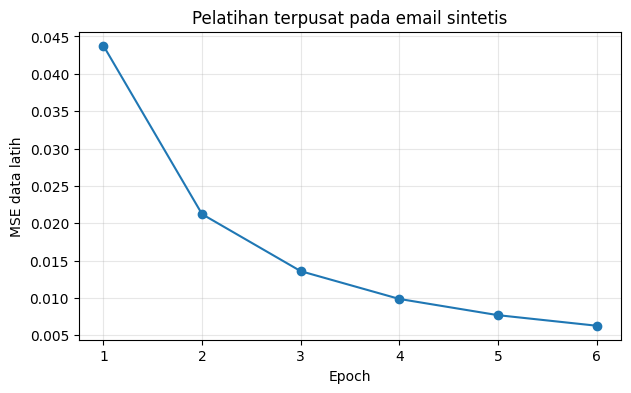

In [5]:
weights_central = weights_awal.copy()
central_loss = []
for epoch in range(6):
    weights_central, loss_hist = latih_lokal(
        weights_central, X_train, y_train, epochs=1, lr=0.03, seed=SEED + epoch
    )
    central_loss.append(loss_dataset(weights_central, X_train, y_train))
    metrik = evaluasi(weights_central, X_test, y_test)
    print(f'Epoch {epoch+1}: loss latih={central_loss[-1]:.4f}, '
          f'loss uji={metrik["loss_mse"]:.4f}, akurasi uji={metrik["akurasi"]:.3f}')

central_metrics = evaluasi(weights_central, X_test, y_test)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(central_loss)+1), central_loss, marker='o')
plt.xlabel('Epoch')
plt.ylabel('MSE data latih')
plt.title('Pelatihan terpusat pada email sintetis')
plt.grid(True, alpha=0.3)
plt.show()

**Interpretasi:** kurva loss yang menurun menunjukkan model menyesuaikan bobotnya terhadap pola pada dataset sintetis. Akurasi yang tinggi pada data ini bukan bukti bahwa model dapat mendeteksi spam nyata; dataset terlalu sederhana dan berasal dari template buatan.

## 6. Mengubah pelatihan menjadi *federated learning*

Kita membagi data latih menjadi tiga kumpulan lokal. Pada setiap putaran:

- Bob, Alice, dan Sue menerima salinan bobot global yang sama.
- Setiap klien melatih bobotnya pada data lokal.
- Koordinator merata-ratakan bobot model klien.
- Bobot rata-rata menjadi titik awal putaran berikutnya.

Di contoh ini setiap klien memiliki jumlah data yang hampir sama, sehingga rata-rata sederhana cukup untuk demonstrasi. Dalam sistem nyata, pembobotan berdasarkan jumlah contoh lokal sering diperlukan. Rata-rata bobot bukan jaminan hasil identik dengan pelatihan terpusat karena urutan, jumlah langkah lokal, dan distribusi data berbeda.

Bob: 214 email, proporsi spam=0.467
Alice: 213 email, proporsi spam=0.549
Sue: 213 email, proporsi spam=0.484
Putaran 1: loss latih=0.1094, akurasi uji=1.000
Putaran 2: loss latih=0.0645, akurasi uji=1.000
Putaran 3: loss latih=0.0442, akurasi uji=1.000
Putaran 4: loss latih=0.0331, akurasi uji=1.000
Putaran 5: loss latih=0.0261, akurasi uji=1.000
Putaran 6: loss latih=0.0214, akurasi uji=1.000


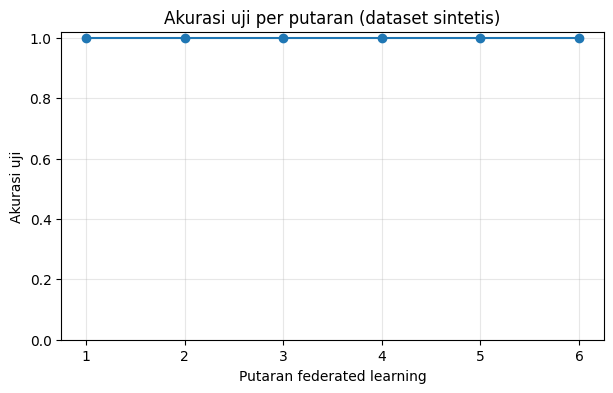

In [6]:
client_indices = np.array_split(np.asarray(idx_train), 3)
clients = {}
for name, ids in zip(['Bob', 'Alice', 'Sue'], client_indices):
    clients[name] = ([X[int(i)] for i in ids], labels[ids])
    print(f'{name}: {len(ids)} email, proporsi spam={labels[ids].mean():.3f}')

weights_fed = weights_awal.copy()
fed_test_accuracy = []
fed_train_loss = []
for round_idx in range(6):
    local_models = []
    for j, (name, (local_X, local_y)) in enumerate(clients.items()):
        w_local, _ = latih_lokal(weights_fed, local_X, local_y,
                                 epochs=1, lr=0.03,
                                 seed=SEED + 100 * round_idx + j)
        local_models.append(w_local)
    # Rata-rata parameter/model hasil tiap klien, mengikuti skema sederhana di buku.
    weights_fed = np.mean(np.stack(local_models, axis=0), axis=0)
    metrics = evaluasi(weights_fed, X_test, y_test)
    fed_test_accuracy.append(metrics['akurasi'])
    fed_train_loss.append(loss_dataset(weights_fed, X_train, y_train))
    print(f'Putaran {round_idx+1}: loss latih={fed_train_loss[-1]:.4f}, '
          f'akurasi uji={metrics["akurasi"]:.3f}')

fed_metrics = evaluasi(weights_fed, X_test, y_test)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(fed_test_accuracy)+1), fed_test_accuracy, marker='o')
plt.xlabel('Putaran federated learning')
plt.ylabel('Akurasi uji')
plt.ylim(0, 1.02)
plt.title('Akurasi uji per putaran (dataset sintetis)')
plt.grid(True, alpha=0.3)
plt.show()

### 6.1 Membandingkan pelatihan terpusat dan terfederasi

Perbandingan ini memeriksa hasil pada pembagian data yang sama. Perbedaan metrik dapat muncul akibat pelatihan lokal, jumlah putaran, dan cara agregasi. Yang penting dari demonstrasi adalah bahwa data lokal dapat tetap di klien selama proses pembelajaran; model/pembaruan tetap berpindah antar pihak.

**Batas privasi:** model atau pembaruan yang dikirim klien bukan otomatis anonim. Bagian berikutnya memperlihatkan risiko sederhana tersebut.

In [7]:
print('Model terpusat : akurasi uji =', round(central_metrics['akurasi'], 3),
      '| MSE =', round(central_metrics['loss_mse'], 4))
print('Model federated: akurasi uji =', round(fed_metrics['akurasi'], 3),
      '| MSE =', round(fed_metrics['loss_mse'], 4))
print('Catatan: hasil ini hanya untuk dataset sintetis dan konfigurasi eksperimen ini.')

Model terpusat : akurasi uji = 1.0 | MSE = 0.0068
Model federated: akurasi uji = 1.0 | MSE = 0.0226
Catatan: hasil ini hanya untuk dataset sintetis dan konfigurasi eksperimen ini.


## 7. Risiko kebocoran: menebak kata dari perubahan bobot

Buku menunjukkan serangan mainan: jika satu klien melatih model embedding pada satu email dan setiap kata memiliki parameter sendiri, pihak yang melihat perubahan bobot dapat mengidentifikasi kata-kata yang muncul. Pada contoh ini, email demonstrasi adalah `my computer password is pizza`.

Serangan ini **sengaja dibuat sangat sederhana**: bobot awal nol, satu contoh, dan model memiliki satu parameter untuk setiap token. Ia menunjukkan mengapa “data mentah tidak dikirim” tidak cukup sebagai jaminan privasi. Serangan ini bukan bukti bahwa setiap model modern selalu dapat dibongkar dengan cara yang sama; kebocoran aktual bergantung pada model, gradien, batch, dan protokol.

In [8]:
email_rahasia = 'my computer password is pizza'
ids_rahasia = [w2i[w] for w in tokenisasi(email_rahasia)]
model_sebelum = np.zeros(len(vocab), dtype=float)
model_sesudah, _ = latih_lokal(
    model_sebelum, [ids_rahasia], np.array([0.0]), epochs=1, lr=0.1, seed=SEED
)
perubahan = model_sesudah - model_sebelum
terdeteksi = [vocab[i] for i in np.flatnonzero(np.abs(perubahan) > 1e-12)]
print('Email pribadi (simulasi):', email_rahasia)
print('Token yang bobotnya berubah:', terdeteksi)
print('Serangan berhasil mengidentifikasi token dalam contoh mainan:', set(terdeteksi) == set(tokenisasi(email_rahasia)))

Email pribadi (simulasi): my computer password is pizza
Token yang bobotnya berubah: ['computer', 'is', 'my', 'password', 'pizza']
Serangan berhasil mengidentifikasi token dalam contoh mainan: True


**Mengapa serangan ini berhasil?** Skor model merupakan penjumlahan embedding kata. Ketika satu contoh digunakan untuk memperbarui model, parameter yang terkait dengan kata pada contoh tersebut berubah, sedangkan parameter kata lain tidak berubah. Pengamat yang mengetahui kosakata dapat membaca pola perubahan itu.

Mitigasi dapat mencakup agregasi aman, *differential privacy* (penambahan noise terukur dengan analisis privasi), pembatasan ukuran/akses pembaruan, dan desain protokol yang sesuai ancaman. Masing-masing memiliki trade-off pada utilitas, biaya komputasi, dan jaminan yang diberikan.

## 8. *Secure aggregation*

*Secure aggregation* dirancang agar koordinator dapat memperoleh **agregat** pembaruan banyak klien tanpa melihat setiap pembaruan secara individual. Buku menghubungkannya dengan gagasan *randomized response* dan *plausible deniability*: informasi agregat dapat berguna tanpa membuka jawaban individu secara langsung.

Di bawah ini adalah simulasi konseptual dengan **masking berpasangan**. Setiap pasangan klien berbagi mask acak: satu klien menambahkan mask, klien lain mengurangkannya. Mask akan saling meniadakan ketika semua pesan dijumlahkan. Ini hanya ilustrasi matematika; bukan implementasi protokol kriptografi yang aman untuk produksi.

In [9]:
rng_mask = np.random.default_rng(SEED + 999)
update_bob = np.array([0.20, -0.10, 0.70])
update_alice = np.array([-0.30, 0.40, 0.10])
update_sue = np.array([0.15, 0.05, -0.20])

mask_ba = rng_mask.normal(size=3)
mask_bs = rng_mask.normal(size=3)
mask_as = rng_mask.normal(size=3)

masked_bob = update_bob + mask_ba + mask_bs
masked_alice = update_alice - mask_ba + mask_as
masked_sue = update_sue - mask_bs - mask_as

agregat_masked = masked_bob + masked_alice + masked_sue
agregat_sebenarnya = update_bob + update_alice + update_sue
print('Pembaruan Bob yang asli     :', update_bob)
print('Pembaruan Bob yang termask  :', masked_bob)
print('Jumlah pembaruan termask    :', agregat_masked)
print('Jumlah pembaruan sebenarnya :', agregat_sebenarnya)
print('Agregat sama:', np.allclose(agregat_masked, agregat_sebenarnya))
assert np.allclose(agregat_masked, agregat_sebenarnya)

Pembaruan Bob yang asli     : [ 0.2 -0.1  0.7]
Pembaruan Bob yang termask  : [-0.8517 -0.632  -0.1512]
Jumlah pembaruan termask    : [0.05 0.35 0.6 ]
Jumlah pembaruan sebenarnya : [0.05 0.35 0.6 ]
Agregat sama: True


**Interpretasi dan batasan:** agregat yang benar dapat diperoleh tanpa membuka nilai asli tiap klien dalam ilustrasi ini. Namun keamanan protokol nyata bergantung pada pengelolaan kunci/mask, jumlah minimum peserta, autentikasi, ketahanan terhadap klien yang gagal, dan model ancaman. Masking sederhana di notebook tidak boleh digunakan untuk melindungi data sungguhan.

*Secure aggregation* juga berbeda dari *differential privacy*: yang pertama membatasi siapa yang dapat melihat pembaruan individu; yang kedua membatasi seberapa jauh keluaran analisis dapat mengungkap kontribusi seseorang, biasanya melalui noise dan parameter privasi yang terukur.

## 9. *Homomorphic encryption*

Enkripsi homomorfik memungkinkan operasi tertentu dilakukan pada ciphertext tanpa terlebih dahulu mendekripsinya. Untuk contoh pada buku, sifat yang dibutuhkan adalah penjumlahan:

$$\operatorname{Enc}(a)+\operatorname{Enc}(b)\;\longrightarrow\;\operatorname{Enc}(a+b).$$

- **Public key** digunakan untuk mengenkripsi nilai.
- **Private key** digunakan untuk mendekripsi hasil.
- *Plaintext* adalah nilai asli; *ciphertext* adalah nilai terenkripsi.

Buku menggunakan pustaka `phe` dengan skema Paillier untuk menunjukkan bahwa enkripsi dua bilangan dapat dijumlahkan saat masih terenkripsi. Sel berikut opsional: bila `phe` belum tersedia, ia akan menampilkan instruksi instalasi dan tetap membiarkan notebook berjalan.

In [10]:
try:
    import phe
except ImportError:
    phe = None
    print('Pustaka phe belum terpasang.')
    print('Untuk menjalankan demonstrasi Paillier, jalankan di notebook: %pip install phe')
else:
    public_key, private_key = phe.generate_paillier_keypair(n_length=1024)
    x_enkripsi = public_key.encrypt(5)
    y_enkripsi = public_key.encrypt(3)
    jumlah_enkripsi = x_enkripsi + y_enkripsi
    hasil_dekripsi = private_key.decrypt(jumlah_enkripsi)
    print('Hasil penjumlahan ciphertext setelah didekripsi:', hasil_dekripsi)
    assert hasil_dekripsi == 8

Pustaka phe belum terpasang.
Untuk menjalankan demonstrasi Paillier, jalankan di notebook: %pip install phe


## 10. Federated learning dengan agregasi homomorfik

Buku menggabungkan dua ide: klien melatih model pada data lokal, lalu mengirim nilai parameter yang telah dienkripsi. Klien menjumlahkan parameter terenkripsi; pemilik private key hanya mendekripsi agregatnya. Dengan demikian, koordinator tidak perlu melihat setiap model klien secara terang.

Sel berikut adalah demonstrasi opsional agregasi vektor bilangan bulat dengan Paillier. Ini memodelkan prinsip enkripsi dan agregasi, **bukan** sistem federated learning produksi yang lengkap. Sistem produksi juga membutuhkan protokol pembaruan model, validasi klien, perlindungan metadata, penanganan kegagalan, dan evaluasi ancaman.

In [11]:
if phe is None:
    print('Dilewati karena phe belum terpasang. Jalankan %pip install phe lalu eksekusi ulang sel ini.')
else:
    pembaruan_klien = np.array([
        [1,  2, -1],
        [3,  4,  2],
        [-1, 6,  5],
    ], dtype=int)
    terenkripsi = [[public_key.encrypt(int(v)) for v in row] for row in pembaruan_klien]
    jumlah_terenkripsi = [terenkripsi[0][j] + terenkripsi[1][j] + terenkripsi[2][j]
                          for j in range(pembaruan_klien.shape[1])]
    jumlah_dekripsi = np.array([private_key.decrypt(v) for v in jumlah_terenkripsi])
    rata_rata = jumlah_dekripsi / len(pembaruan_klien)
    print('Jumlah update setelah dekripsi agregat:', jumlah_dekripsi)
    print('Rata-rata update:', rata_rata)
    assert np.allclose(jumlah_dekripsi, pembaruan_klien.sum(axis=0))

Dilewati karena phe belum terpasang. Jalankan %pip install phe lalu eksekusi ulang sel ini.


## 11. Membandingkan mekanisme privasi

| Pendekatan | Yang dilakukan | Batas penting |
|---|---|---|
| Federated learning | Data mentah tetap di klien; parameter/pembaruan berpindah | Pembaruan masih bisa membocorkan informasi |
| Secure aggregation | Koordinator menerima agregat tanpa melihat tiap update secara langsung | Membutuhkan protokol aman; tidak otomatis mencegah semua inferensi dari agregat |
| Homomorphic encryption | Operasi tertentu dilakukan pada data terenkripsi | Biaya komputasi/komunikasi lebih tinggi; skema dan implementasi harus benar |
| Differential privacy | Membatasi kebocoran melalui noise dengan parameter privasi terukur | Ada trade-off akurasi dan perlu analisis komposisi privasi |

Keempatnya tidak saling menggantikan sepenuhnya. Sistem yang membutuhkan jaminan kuat dapat menggabungkan beberapa pendekatan, tetapi desain harus ditentukan oleh model ancaman, bukan hanya dengan menambahkan istilah “federated” atau “encrypted”.

## 12. Kesimpulan Bab 15

1. **Federated learning** memungkinkan beberapa pihak berkontribusi pada model tanpa memusatkan seluruh data mentah.
2. Contoh klasifikasi spam memperlihatkan alur pelatihan terpusat dan rata-rata model dari klien lokal.
3. **Pembaruan model dapat membocorkan informasi**; menjaga data mentah tetap lokal bukan jaminan privasi mutlak.
4. **Secure aggregation** berupaya menyembunyikan pembaruan individual dengan hanya membuka agregat.
5. **Homomorphic encryption** memungkinkan penjumlahan nilai terenkripsi, tetapi membutuhkan implementasi kriptografi yang benar.
6. Privasi dan utilitas perlu dievaluasi bersama; demonstrasi kecil tidak cukup untuk menyatakan suatu sistem aman.